# Chapitre 16 - Cours 1 : boosting et chemins de régularisation

Ce premier notebook couvre la section 16.2 du livre. Nous y montrons que le
**boosting avec rétrécissement** (« shrinkage ») se comporte comme un **lasso** posé
dans l'espace gigantesque de toutes les fonctions de base possibles (par exemple
tous les arbres), puis nous en tirons trois leçons :

1. la régression *forward stagewise* incrémentale (algorithme 16.1) suit
   approximativement le chemin du lasso (figure 16.1) ;
2. le principe du **« pari sur la parcimonie »** (*bet on sparsity*) explique
   pourquoi une pénalité $L_1$ est préférable en grande dimension ;
3. les chemins de régularisation du boosting sont « bien élevés » (monotones,
   figures 16.3–16.4) et convergent vers une solution de **marge $L_1$ maximale**
   (figure 16.5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch16_ensembles import (standardize, forward_stagewise, lasso_path_cd,
                                ridge_path_df, block_correlated_data,
                                l1_arc_length, adaboost_shrunk)

## 1. Qu'est-ce qu'un ensemble ?

L'**apprentissage ensembliste** construit un prédicteur en combinant de nombreux
modèles simples, appelés *apprenants de base* ou *apprenants faibles*. Nous en avons
déjà rencontré plusieurs :

- le **bagging** (section 8.7) et les **forêts aléatoires** (chapitre 15) : un
  comité d'arbres vote ;
- le **boosting** (chapitre 10) : le comité est construit séquentiellement et les
  votes sont pondérés ;
- le **stacking** (section 8.8) ;
- plus généralement toute méthode à *dictionnaire* (splines de régression, etc.),
  où les fonctions de base jouent le rôle des apprenants faibles.

On peut décomposer la démarche en deux tâches : (i) produire une population
d'apprenants de base à partir des données ; (ii) les combiner en un prédicteur final.

> **Remarque (codes correcteurs d'erreurs).** Un ancêtre des ensembles est la méthode
> ECOC pour la classification à $K$ classes : chaque classe $k$ reçoit un mot de code
> binaire $(C_{k1},\dots,C_{kL})$ (une ligne de la matrice de codage, tableau 16.1 du
> livre) ; on apprend un classifieur à deux classes par colonne $\ell$, qui estime
> $\hat p_\ell(x)$, la probabilité que le bit $\ell$ vaille 1 ; puis on affecte $x$ à la
> classe minimisant $\delta_k(x)=\sum_{\ell=1}^L |C_{k\ell}-\hat p_\ell(x)|$. Les bits
> redondants permettent de « corriger » quelques erreurs des classifieurs ; en pratique
> le gain vient surtout d'une réduction de variance, comme pour le bagging.

## 2. Régression pénalisée sur un dictionnaire de fonctions de base

Notons $\mathcal T=\{T_k\}_{k=1}^K$ le dictionnaire de **tous** les arbres de régression à
$J$ feuilles que l'on peut construire sur les données d'apprentissage ($K$ est
astronomique). On considère le modèle linéaire (éq. (16.1) du livre)
$$
f(x)=\sum_{k=1}^K \alpha_k\,T_k(x).
$$
Comme $K\gg N$, les moindres carrés seuls n'ont aucun sens (une infinité de solutions
interpolent les données) : il faut **régulariser**. On résout donc (éq. (16.2))
$$
\hat\alpha(\lambda)=\arg\min_{\alpha}\ \sum_{i=1}^N\Big(y_i-\sum_{k=1}^K\alpha_kT_k(x_i)\Big)^2+\lambda\,J(\alpha),
$$
avec $J(\alpha)=\sum_k\alpha_k^2$ (ridge, éq. (16.3)) ou $J(\alpha)=\sum_k|\alpha_k|$
(lasso, éq. (16.4)).

> **Rappel (lasso, section 3.4).** Pour $\lambda$ modéré ou grand, la solution du lasso
> est **parcimonieuse** : beaucoup de $\hat\alpha_k(\lambda)$ sont exactement nuls. Les
> coefficients non nuls sont de plus *rétrécis* : $|\hat\alpha_k(\lambda)|<|\hat\alpha_k(0)|$.
> Lorsque $\lambda$ croît, tous les coefficients diminuent et finissent par s'annuler.

L'idée est séduisante : seule une petite fraction des arbres est sans doute utile pour
approcher une fonction cible donnée. Mais $K$ est bien trop grand pour résoudre (16.2)
directement. C'est ici qu'intervient une stratégie *pas à pas*.

## 3. L'algorithme forward stagewise incrémental (algorithme 16.1)

1. Initialiser $\check\alpha_k=0$ pour tout $k$ ; choisir un petit pas $\varepsilon>0$ et un
   grand nombre d'itérations $M$.
2. Pour $m=1,\dots,M$ :
   - (a) $(\beta^*,k^*)=\arg\min_{\beta,k}\sum_i\big(y_i-\sum_l\check\alpha_lT_l(x_i)-\beta T_k(x_i)\big)^2$ ;
   - (b) $\check\alpha_{k^*}\leftarrow\check\alpha_{k^*}+\varepsilon\cdot\operatorname{signe}(\beta^*)$.
3. Renvoyer $f_M(x)=\sum_k\check\alpha_kT_k(x)$.

Au départ tous les coefficients sont nuls (ce qui correspond à $\lambda=\infty$) ; à
chaque étape un seul coefficient bouge, d'une quantité minuscule.

**Comment calculer l'étape (a).** Notons $r=y-\sum_l\check\alpha_l\mathbf T_l$ le résidu
courant et $\mathbf t_k=(T_k(x_1),\dots,T_k(x_N))^T$. Pour $k$ fixé, la fonction
$\beta\mapsto\|r-\beta\mathbf t_k\|^2$ est un trinôme du second degré en $\beta$ ; sa
dérivée $-2\,\mathbf t_k^T(r-\beta\mathbf t_k)$ s'annule en
$\beta_k=\mathbf t_k^Tr/\|\mathbf t_k\|^2$. En développant le carré, le minimum vaut
$$
\|r-\beta_k\mathbf t_k\|^2=\|r\|^2-2\beta_k\,\mathbf t_k^Tr+\beta_k^2\|\mathbf t_k\|^2
=\|r\|^2-\frac{(\mathbf t_k^Tr)^2}{\|\mathbf t_k\|^2}.
$$
Minimiser en $k$ revient donc à **maximiser** $(\mathbf t_k^Tr)^2/\|\mathbf t_k\|^2$ ; si
les bases sont standardisées, c'est choisir la base la plus **corrélée** (en valeur
absolue) au résidu, et $\operatorname{signe}(\beta^*)=\operatorname{signe}(\mathbf t_{k^*}^Tr)$.
C'est ce que code `forward_stagewise` du module `esl/ch16_ensembles.py`.

> **Intuition.** On ne fait jamais confiance à une seule base : on avance d'un pas
> minuscule dans la direction qui améliore le plus l'ajustement, puis on réévalue.
> Après $M$ étapes, beaucoup de coefficients sont encore nuls (jamais choisis), et les
> autres sont plus petits que leurs valeurs des moindres carrés : qualitativement,
> c'est un lasso, avec $M$ qui joue le rôle de $1/\lambda$.

## 4. Figure 16.1 : lasso et forward stagewise sur les données prostate

Pour visualiser, on remplace les arbres par les 8 variables explicatives elles-mêmes
(régression linéaire multiple, chapitre 3). On standardise les prédicteurs de
l'échantillon d'apprentissage et on centre la réponse `lpsa`.

In [2]:
df = datasets.load_prostate()
train = df[df["train"]]
names = [c for c in df.columns if c not in ("lpsa", "train")]
Xp, _, _ = standardize(train[names].to_numpy(float))
yp = train["lpsa"].to_numpy(float)
yp_c = yp - yp.mean()
print("N =", Xp.shape[0], " p =", Xp.shape[1])

N = 67  p = 8


Le lasso est calculé par **descente de coordonnées** (`lasso_path_cd`) sur une grille
fine de $\lambda$. On représente les coefficients en fonction de la borne
$t=\sum_k|\alpha_k|$, comme dans la figure du livre.

In [3]:
lams, _, coef_lasso = lasso_path_cd(Xp, yp, n_lambdas=200, lambda_ratio=1e-4, tol=1e-10)
t_lasso = np.abs(coef_lasso).sum(axis=1)
print("t maximal (moindres carrés) : %.3f" % t_lasso[-1])

t maximal (moindres carrés) : 2.241


Puis l'algorithme 16.1 avec $\varepsilon=0{,}01$ et $M=250$ étapes.

In [4]:
path_fs = forward_stagewise(Xp, yp_c, eps=0.01, n_steps=250)
print("coefficients après 250 pas :", np.round(path_fs[-1], 3))
print("moindres carrés            :", np.round(np.linalg.lstsq(Xp, yp_c, rcond=None)[0], 3))

coefficients après 250 pas : [ 0.71  0.29 -0.14  0.21  0.31 -0.29 -0.02  0.27]
moindres carrés            : [ 0.711  0.29  -0.141  0.21   0.307 -0.287 -0.021  0.275]


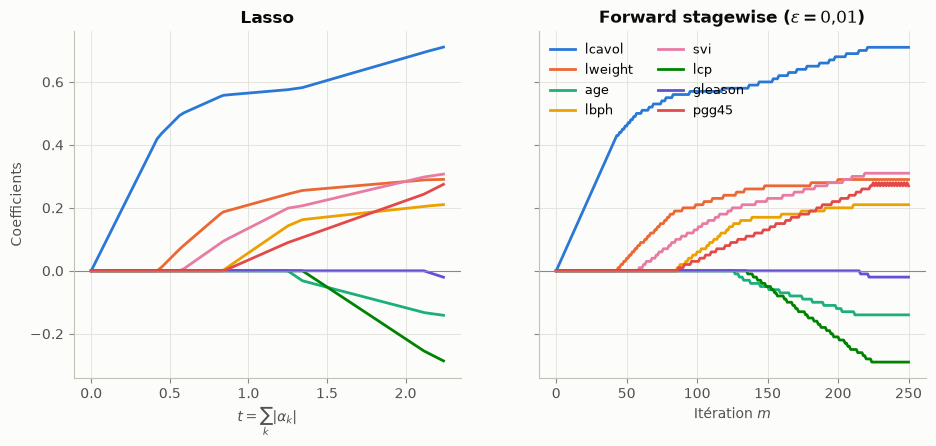

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for j, name in enumerate(names):
    col = COLORS[j % len(COLORS)]
    axes[0].plot(t_lasso, coef_lasso[:, j], color=col, label=name)
    axes[1].plot(np.arange(251), path_fs[:, j], color=col, label=name)
axes[0].set(title="Lasso", xlabel=r"$t=\sum_k|\alpha_k|$", ylabel="Coefficients")
axes[1].set(title=r"Forward stagewise ($\varepsilon=0{,}01$)", xlabel="Itération $m$")
axes[1].legend(loc="upper left", ncol=2)
for ax in axes:
    ax.axhline(0, color=GRAY, lw=0.8)
plt.show()

La ressemblance est frappante : les variables entrent dans le même ordre (`lcavol`,
puis `svi`, `lweight`…) et les profils ont la même allure. Comme chaque pas augmente
la norme $L_1$ d'au plus $\varepsilon$, l'itération $m$ correspond grossièrement à
$t\approx m\varepsilon$ : les deux axes horizontaux sont comparables.

Pour une comparaison directe, superposons les deux chemins en fonction de la norme
$L_1$ des coefficients.

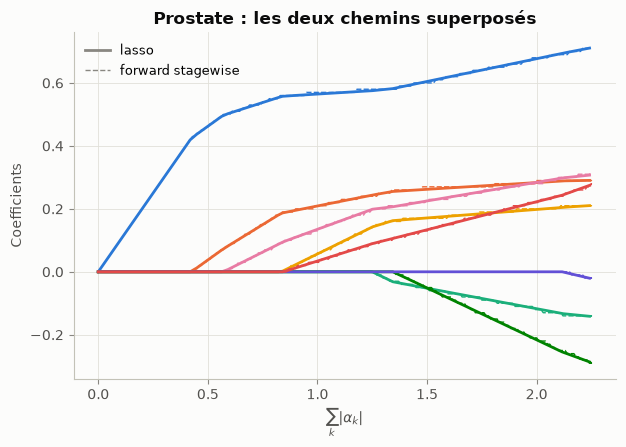

In [6]:
t_fs = np.abs(path_fs).sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 4.5))
for j, name in enumerate(names):
    col = COLORS[j % len(COLORS)]
    ax.plot(t_lasso, coef_lasso[:, j], color=col, lw=2)
    ax.plot(t_fs, path_fs[:, j], color=col, lw=1, ls="--")
ax.plot([], [], color=GRAY, lw=2, label="lasso")
ax.plot([], [], color=GRAY, lw=1, ls="--", label="forward stagewise")
ax.set(title="Prostate : les deux chemins superposés",
       xlabel=r"$\sum_k|\alpha_k|$", ylabel="Coefficients")
ax.legend()
plt.show()

## 5. Un cas où l'équivalence est exacte : bases orthonormées

Le livre affirme que si les fonctions de base sont **non corrélées**, alors quand
$\varepsilon\to0$ et $M\to\infty$ avec $M\varepsilon\to t$, l'algorithme 16.1 donne
**exactement** la solution du lasso de borne $t$. Vérifions-le dans le cas où les
colonnes $\mathbf x_k$ sont orthonormées ($X^TX=I$).

**Le lasso.** Posons $z=X^Ty$. Comme $X^TX=I$, on développe
$\|y-X\alpha\|^2=\|y\|^2-2z^T\alpha+\|\alpha\|^2=\|y\|^2-\|z\|^2+\sum_k(z_k-\alpha_k)^2$ :
le problème se **sépare** coordonnée par coordonnée, et (section 3.4.3) la solution
est le *seuillage doux*
$$
\hat\alpha_k=\operatorname{signe}(z_k)\,(|z_k|-\gamma)_+ ,
$$
où le seuil $\gamma\ge 0$ est choisi pour que $\sum_k|\hat\alpha_k|=t$.

**Forward stagewise.** Le résidu vaut $r=y-X\alpha$, donc les corrélations sont
$c=X^Tr=z-\alpha$ (car $X^TX=I$). À chaque pas, l'algorithme choisit la coordonnée de
plus grand $|z_k-\alpha_k|$ et déplace $\alpha_k$ de $\varepsilon$ **vers** $z_k$ : il
« rabote » la plus grande des quantités $|z_k-\alpha_k|$. Quand $\varepsilon\to0$, toutes
les coordonnées déjà touchées partagent donc un même niveau
$|z_k-\alpha_k|=\gamma$, avec $\alpha_k$ du signe de $z_k$, tandis que les coordonnées
jamais touchées vérifient $|z_k|\le\gamma$. C'est exactement le seuillage doux
ci-dessus ; et la norme $L_1$ vaut $M\varepsilon$ puisque chaque pas l'augmente de
$\varepsilon$ (les coefficients ne changent jamais de signe).

In [7]:
rng = np.random.RandomState(0)
Q, _ = np.linalg.qr(rng.randn(100, 6))       # 6 colonnes orthonormées
y_orth = Q @ np.array([2.5, -1.8, 1.2, 0.6, -0.3, 0.0]) + 0.2 * rng.randn(100)
eps = 1e-3
path_orth = forward_stagewise(Q, y_orth, eps=eps, n_steps=7000)
z = Q.T @ y_orth
t_grid = eps * np.arange(7001)
# lasso exact : seuillage doux pour chaque borne t
gam_grid = np.linspace(np.abs(z).max(), 0, 2000)
lasso_orth = np.sign(z) * np.maximum(np.abs(z)[None, :] - gam_grid[:, None], 0)
t_orth = np.abs(lasso_orth).sum(axis=1)

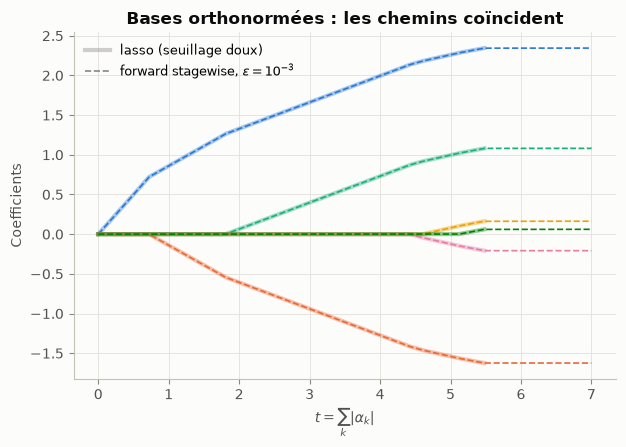

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in range(6):
    ax.plot(t_orth, lasso_orth[:, k], color=COLORS[k], lw=3, alpha=0.4)
    ax.plot(t_grid, path_orth[:, k], color=COLORS[k], lw=1.2, ls="--")
ax.plot([], [], color=GRAY, lw=3, alpha=0.4, label="lasso (seuillage doux)")
ax.plot([], [], color=GRAY, lw=1.2, ls="--", label=r"forward stagewise, $\varepsilon=10^{-3}$")
ax.set(title="Bases orthonormées : les chemins coïncident",
       xlabel=r"$t=\sum_k|\alpha_k|$", ylabel="Coefficients")
ax.legend()
plt.show()

Les chemins sont confondus (à $\varepsilon$ près). Le livre précise que l'égalité reste
vraie sans orthogonalité lorsque les coefficients du lasso sont des fonctions
**monotones** de $\lambda$ - ce qui est fréquent quand les variables sont peu
corrélées. Nous verrons au paragraphe 8 ce qui se passe avec des variables très
corrélées.

## 6. Lien avec le boosting d'arbres

Le boosting d'arbres avec rétrécissement (algorithme 10.3 et éq. (10.41) :
$f_m=f_{m-1}+\nu\,T_m$) ressemble beaucoup à l'algorithme 16.1, le taux $\nu$ jouant
le rôle de $\varepsilon$. Pour la perte quadratique, la seule différence est que
l'arbre « optimal » $T_{k^*}$ (celui qui ajuste le mieux le résidu parmi **tous** les
arbres) est approché par la construction gloutonne descendante usuelle.

> **À retenir.** Le boosting avec rétrécissement peut se lire comme une régression
> régularisée, monotone, sur l'ensemble de tous les arbres possibles, avec une
> pénalité de type lasso (16.4). Sans rétrécissement ($\nu=1$), il s'apparente plutôt
> à la régression *pas à pas* (forward stepwise), voire à la sélection du meilleur
> sous-ensemble (pénalité $\sum_k|\alpha_k|^0$, le nombre de coefficients non nuls),
> souvent trop gloutonnes - d'où les gains spectaculaires du rétrécissement.

## 7. Le principe du « pari sur la parcimonie »

La pénalité $L_2$ est commode (astuce du noyau, section 12.3.7 : on n'a jamais besoin
de parcourir les fonctions de base une à une), alors que la pénalité $L_1$ impose une
recherche explicite. Pourquoi alors préférer $L_1$ ?

Imaginons $N=10\,000$ observations et un modèle combinant un million d'arbres.

- Si les vrais coefficients sont **gaussiens** (scénario *dense*), le meilleur
  prédicteur au sens bayésien est la régression ridge (exercice 3.6)… mais aucune
  méthode ne fait bien : il y a beaucoup trop de coefficients à estimer.
- Si seuls 1000 coefficients sont non nuls (scénario *parcimonieux*), le lasso
  peut très bien faire, la ridge non.

> **Principe (« bet on sparsity »).** *Utiliser une procédure qui marche bien dans les
> problèmes parcimonieux, puisque aucune procédure ne marche bien dans les problèmes
> denses.*

Nuances importantes : le caractère parcimonieux dépend de la vraie fonction **et**
du dictionnaire choisi ; il est relatif à la taille de l'échantillon et au rapport
bruit/signal (NSR) ; enfin un dictionnaire plus grand peut rendre la représentation
plus parcimonieuse mais rend la recherche plus difficile (plus de variance).

Faisons une version réduite de la simulation de la figure 16.2 (la version complète
est l'objet de l'exercice 16.4) : $N=50$ observations, $p=300$ prédicteurs gaussiens
indépendants, $y=X\beta+\varepsilon$ avec $\varepsilon\sim\mathcal N(0,1)$ et $\beta$ remis à
l'échelle pour que le rapport bruit/signal
$\mathrm{NSR}=\operatorname{Var}(\varepsilon)/\operatorname{Var}(X^T\beta)=1/\|\beta\|^2$ vaille
$0{,}2$. Pour un nouveau point $x\sim\mathcal N(0,I)$, l'erreur de prédiction de
$\hat\beta$ vaut exactement $1+\|\hat\beta-\beta\|^2$ (on développe le carré et on
utilise $\mathbb E[xx^T]=I$) ; on rapporte la **part d'erreur expliquée**
$1-\mathrm{Err}(\hat\beta)/\mathrm{Err}(0)$, pour le meilleur $\lambda$ du chemin.

In [9]:
from sklearn.linear_model import lars_path   # chemin exact du lasso (algorithme LARS)


def best_explained(X, y, beta, method):
    """Meilleure part d'erreur expliquée le long du chemin (erreur test exacte)."""
    Xc, yc = X - X.mean(0), y - y.mean()
    if method == "lasso":
        _, _, coefs = lars_path(Xc, yc, method="lasso", max_iter=500)
        coefs = coefs.T
    else:
        _, coefs = ridge_path_df(Xc, yc, np.linspace(1, 49, 49))
    err = 1 + ((coefs - beta) ** 2).sum(axis=1)
    return 1 - err.min() / (1 + beta @ beta)


rng = np.random.RandomState(0)
res = {}
for scen, k in [("dense (300)", 300), ("parcimonieux (10)", 10)]:
    for method in ("lasso", "ridge"):
        vals = []
        for rep in range(15):
            beta = np.zeros(300)
            beta[:k] = rng.randn(k)
            beta *= np.sqrt(1 / 0.2) / np.linalg.norm(beta)     # NSR = 0,2
            X = rng.randn(50, 300)
            y = X @ beta + rng.randn(50)
            vals.append(best_explained(X, y, beta, method))
        res[(scen, method)] = vals
print({key: round(np.median(v), 2) for key, v in res.items()})

{('dense (300)', 'lasso'): np.float64(0.01), ('dense (300)', 'ridge'): np.float64(0.1), ('parcimonieux (10)', 'lasso'): np.float64(0.59), ('parcimonieux (10)', 'ridge'): np.float64(0.09)}


Ici `lars_path` de scikit-learn sert uniquement à obtenir rapidement le chemin
**exact** du lasso (algorithme LARS de la section 3.8.1) ; notre descente de
coordonnées donne les mêmes solutions mais serait plus lente sur des centaines de
simulations.

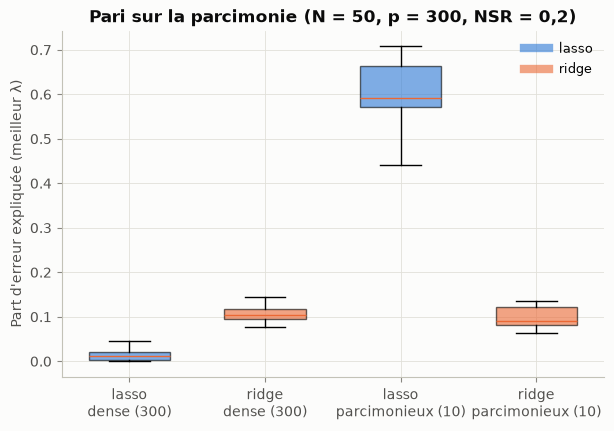

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
keys = list(res)
bp = ax.boxplot([res[k] for k in keys], patch_artist=True, widths=0.6)
for patch, key in zip(bp["boxes"], keys):
    patch.set_facecolor(BLUE if key[1] == "lasso" else ORANGE)
    patch.set_alpha(0.6)
ax.set_xticks(range(1, 5))
ax.set_xticklabels(["%s\n%s" % (m, s) for s, m in keys])
ax.plot([], [], color=BLUE, lw=6, alpha=0.6, label="lasso")
ax.plot([], [], color=ORANGE, lw=6, alpha=0.6, label="ridge")
ax.set(title="Pari sur la parcimonie (N = 50, p = 300, NSR = 0,2)",
       ylabel="Part d'erreur expliquée (meilleur λ)")
ax.legend()
plt.show()

Dans le scénario dense, ridge fait (un peu) mieux que le lasso, mais les deux
n'expliquent presque rien. Dans le scénario parcimonieux, le lasso explique une large
part de l'erreur, la ridge très peu : c'est exactement le pari sur la parcimonie.

## 8. Chemins de régularisation avec des variables très corrélées (figures 16.3 et 16.4)

Le livre simule un dictionnaire de $p=1000$ variables gaussiennes, très corrélées
($\rho=0{,}95$) à l'intérieur de 50 blocs de 20, indépendantes d'un bloc à l'autre ; le
vrai modèle a un coefficient non nul (gaussien) par bloc, et le bruit a un rapport
bruit/signal de $0{,}72$. Les blocs imitent les fortes corrélations entre arbres
voisins ; $N=60$. La fonction `block_correlated_data` implémente ce mécanisme
(voir l'exercice 16.1 pour le détail).

In [11]:
rng = np.random.RandomState(0)
Xb, yb, beta_b, sigma_b = block_correlated_data(60, rng=rng)
Xb_test, yb_test, _, _ = block_correlated_data(5000, beta=beta_b, rng=rng)
Xb_s, mb, sb = standardize(Xb)
Xb_test_s, _, _ = standardize(Xb_test, mb, sb)
yb_c = yb - yb.mean()
print("p =", Xb.shape[1], " coefficients non nuls :", np.sum(beta_b != 0),
      " sigma = %.2f" % sigma_b)

p = 1000  coefficients non nuls : 50  sigma = 6.00


Le chemin exact du lasso est obtenu par LARS. Pour le **forward stagewise
infinitésimal** $\mathrm{FS}_0$ (limite $\varepsilon\to0$ de l'algorithme 16.1), nous
utilisons simplement l'algorithme 16.1 avec un très petit pas $\varepsilon=0{,}005$.

In [12]:
_, _, cl = lars_path(Xb_s, yb_c, method="lasso", max_iter=2000)
coef_lasso_b = cl.T
L1_lasso = np.abs(coef_lasso_b).sum(axis=1)
path_fs_b = forward_stagewise(Xb_s, yb_c, eps=0.005, n_steps=12000)
L1_fs = np.abs(path_fs_b).sum(axis=1)
print("norme L1 finale : lasso %.1f, stagewise %.1f" % (L1_lasso[-1], L1_fs[-1]))

norme L1 finale : lasso 39.7, stagewise 46.8


Avec $p>N$, les deux méthodes finissent par interpoler les données ; on normalise
l'axe horizontal par la norme $L_1$ finale de chaque chemin, $|\alpha(m)|/|\alpha(\infty)|$.
On ne trace que les variables qui deviennent importantes.

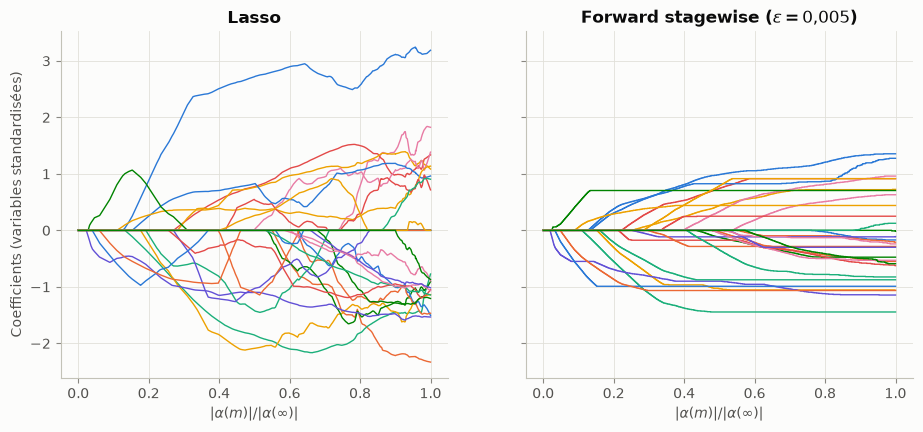

In [13]:
big = np.argsort(-np.abs(coef_lasso_b).max(axis=0))[:30]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for i, j in enumerate(big):
    col = COLORS[i % len(COLORS)]
    axes[0].plot(L1_lasso / L1_lasso[-1], coef_lasso_b[:, j], color=col, lw=1)
    axes[1].plot(L1_fs / L1_fs[-1], path_fs_b[:, j], color=col, lw=1)
axes[0].set(title="Lasso", xlabel=r"$|\alpha(m)|/|\alpha(\infty)|$",
            ylabel="Coefficients (variables standardisées)")
axes[1].set(title=r"Forward stagewise ($\varepsilon=0{,}005$)",
            xlabel=r"$|\alpha(m)|/|\alpha(\infty)|$")
plt.show()

Au début les profils se ressemblent ; dans la seconde moitié, ceux du lasso
**oscillent fortement** (des variables d'un même bloc se relaient, entrent et sortent),
alors que ceux du forward stagewise sont plus lisses et presque monotones. C'est la
multicolinéarité qui perturbe le lasso (exercice 3.28).

Comparons maintenant l'erreur quadratique moyenne sur un grand échantillon test, en
fonction de la norme $L_1$ des coefficients (figure 16.4).

In [ ]:
def test_mse(path):
    pred = yb.mean() + Xb_test_s @ path.T
    return ((yb_test[:, None] - pred) ** 2).mean(axis=0)


mse_lasso = test_mse(coef_lasso_b)
sub = np.arange(0, len(path_fs_b), 20)
mse_fs = test_mse(path_fs_b[sub])